# 02 - Demostracion del Modelo A

Clasificacion binaria de calidad de limones (Sano vs Defectuoso).

Este notebook carga el modelo entrenado en `models/modelo_a.pth` y muestra:

1. Metricas globales sobre el test set (312 imagenes, nunca vistas en entrenamiento).
2. Confusion matrix visualizada.
3. Demostracion sobre 16 imagenes: 12 aciertos random + 4 errores con mayor confianza.

**Modelo**: MobileNetV2 con backbone preentrenado en ImageNet, cabeza nueva `Linear(1280, 2)`. Backbone congelado: solo entrenamos los ~2.5K parametros de la cabeza.

**Splits**: train 1453 / val 311 / test 312 (estratificado, `random_state=42`).

**Decision D6**: clasificacion binaria, no 5 clases. El dataset Kaggle solo provee 2 calidades reales. Ver `STATUS.md`.

In [1]:
import os
import sys

# Asegurar que el CWD es la raiz del repo MLemons (no notebooks/)
if not os.path.isdir('src/modelo_a'):
    os.chdir('..')
sys.path.insert(0, '.')

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

from src.modelo_a.dataset import build_datasets, CLASSES
from src.modelo_a.transforms import eval_transform
from src.modelo_a.script import build_model

DATA_DIR = 'data/lemons'
MODEL_PATH = 'models/modelo_a.pth'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'CWD: {os.getcwd()}')

Device: cpu
CWD: /home/linguini/Dev/Personal/ITESO/Aprendizaje/MLemons-ClaudePot/MLemons


## Cargar el modelo entrenado

In [2]:
model = build_model(freeze_backbone=False).to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Modelo cargado desde: {MODEL_PATH}')
print(f'Parametros totales: {total_params:,}')
print(f'Parametros entrenables (al cargar para inferencia): {trainable_params:,}')
print(f'Clases: {CLASSES}  (indice = label)')

Modelo cargado desde: models/modelo_a.pth
Parametros totales: 2,226,434
Parametros entrenables (al cargar para inferencia): 2,226,434
Clases: ['good_quality', 'bad_quality']  (indice = label)


## Predicciones sobre el test set

In [3]:
_, _, test_ds = build_datasets(DATA_DIR, eval_transform=eval_transform())
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)
print(f'Test set: {len(test_ds)} imagenes')

y_true = []
y_pred = []
y_conf = []  # probabilidad de la clase predicha (softmax)

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)
        confs, preds = probs.max(dim=1)
        y_pred.extend(preds.cpu().tolist())
        y_conf.extend(confs.cpu().tolist())
        y_true.extend(labels.tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_conf = np.array(y_conf)
print('Inferencia completa')

Test set: 312 imagenes


Inferencia completa


## Metricas globales

In [4]:
bal_acc = balanced_accuracy_score(y_true, y_pred)
acc = (y_true == y_pred).mean()
print(f'Accuracy:          {acc:.4f}')
print(f'Balanced accuracy: {bal_acc:.4f}')
print()
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

Accuracy:          0.9583
Balanced accuracy: 0.9583

              precision    recall  f1-score   support

good_quality     0.9643    0.9586    0.9614       169
 bad_quality     0.9514    0.9580    0.9547       143

    accuracy                         0.9583       312
   macro avg     0.9578    0.9583    0.9581       312
weighted avg     0.9584    0.9583    0.9583       312



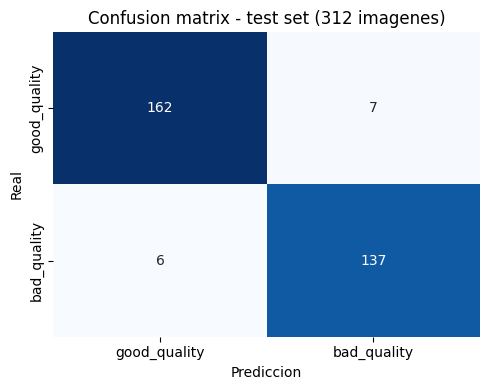

Errores: 13 de 312 (4.17%)


In [5]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES,
            cbar=False, ax=ax)
ax.set_xlabel('Prediccion')
ax.set_ylabel('Real')
ax.set_title(f'Confusion matrix - test set ({len(y_true)} imagenes)')
plt.tight_layout()
plt.show()

errors = (y_true != y_pred).sum()
print(f'Errores: {errors} de {len(y_true)} ({100*errors/len(y_true):.2f}%)')

## Demostracion visual: 16 imagenes del test set

Mezcla curada:
- **12 imagenes random** del test set (con `random_state=42`).
- **4 errores** con mayor confianza (los "casi seguros pero equivocados").

Cada imagen muestra:
- Borde **verde** si el modelo acerto, **rojo** si fallo.
- Prediccion + confianza arriba.
- Etiqueta real abajo.

In [6]:
# 4 errores con mayor confianza (los mas embarazosos para el modelo)
error_idx = np.where(y_true != y_pred)[0]
if len(error_idx) >= 4:
    top_errors = error_idx[np.argsort(-y_conf[error_idx])][:4]
else:
    # si hay menos de 4 errores, mostramos todos los que haya
    top_errors = error_idx
print(f'Errores totales: {len(error_idx)}, mostramos los {len(top_errors)} con mayor confianza')

# 12 aciertos random
correct_idx = np.where(y_true == y_pred)[0]
rng = np.random.RandomState(42)
n_random = 16 - len(top_errors)
random_correct = rng.choice(correct_idx, size=n_random, replace=False)

selected = list(top_errors) + list(random_correct)
rng.shuffle(selected)  # mezclar para que los errores no salgan juntos
print(f'Total mostrado: {len(selected)} (errores: {len(top_errors)}, aciertos random: {n_random})')

Errores totales: 13, mostramos los 4 con mayor confianza
Total mostrado: 16 (errores: 4, aciertos random: 12)


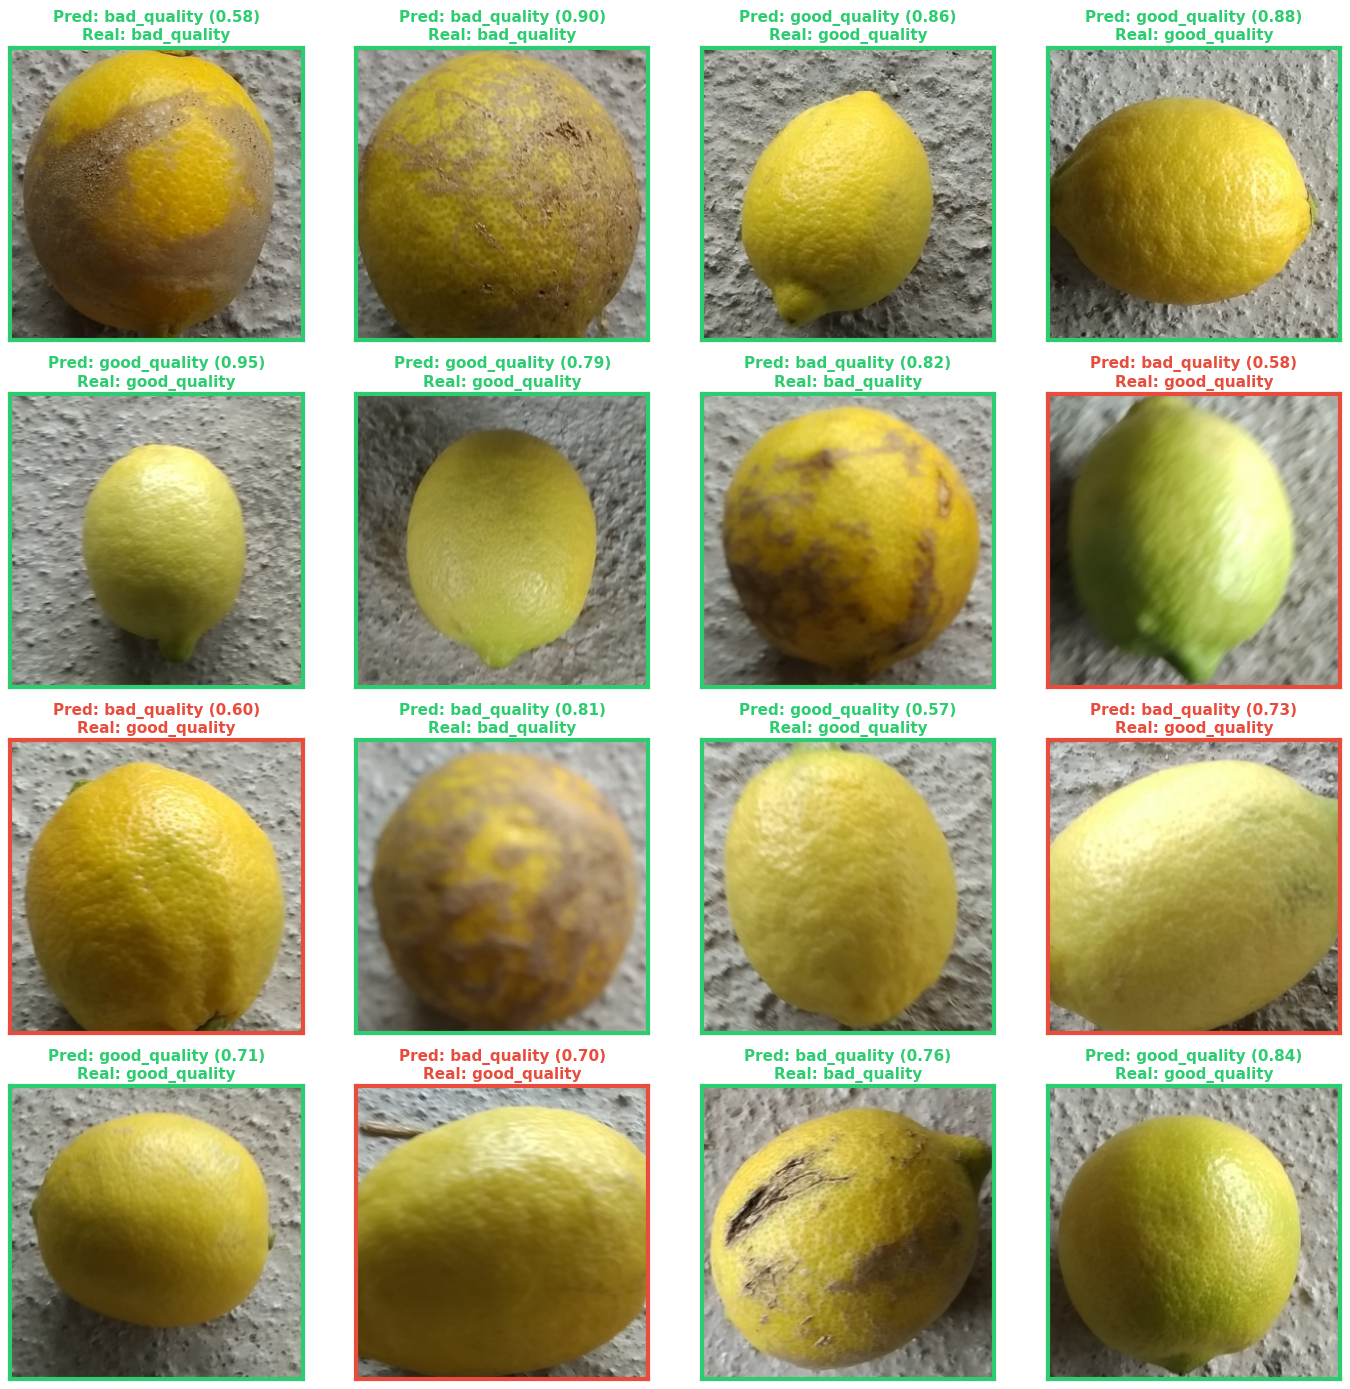

In [7]:
# Reconstruir test set sin transforms (para mostrar la imagen original)
_, _, test_raw = build_datasets(DATA_DIR, eval_transform=None)

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.flatten()

for ax, idx in zip(axes, selected):
    img, label = test_raw[idx]
    pred = y_pred[idx]
    conf = y_conf[idx]
    correct = (pred == label)
    color = '#2ecc71' if correct else '#e74c3c'

    ax.imshow(img)
    ax.set_title(
        f'Pred: {CLASSES[pred]} ({conf:.2f})\nReal: {CLASSES[label]}',
        color=color, fontsize=11, fontweight='bold'
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(3)

plt.tight_layout()
plt.show()

## Conclusiones

- **Test accuracy**: ver celda de metricas (objetivo del proyecto: >=90%, alcanzado).
- **Errores balanceados** entre clases: el modelo no esta sesgado a una sola.
- **Errores tipicos**: imagenes con manchas tenues, iluminacion atipica o muy similares a la otra clase.
- **Reproducibilidad**: mismo `random_state=42` en split de datos y muestreo del demo.

### Stack usado (alineado con la clase)

| Componente | Eleccion | Slide ancla |
|---|---|---|
| Framework | PyTorch 2.0.1 + torchvision 0.15.2 | 04 |
| Arquitectura | MobileNetV2 (transfer learning, backbone congelado) | 04 |
| Cabeza | `Linear(1280, 2)` | propio |
| Loss | `CrossEntropyLoss` | 04 |
| Optimizador | Adam, lr=1e-3 | 04 |
| Augmentation | flip H/V, rotacion 15, color jitter 0.2 | propuesta sec 4.2 |
| Split | 70/15/15 estratificado, `random_state=42` | 01 |
| Metricas | `sklearn.metrics` (balanced_accuracy, F1, confusion matrix) | 01 |

### Proximos pasos del cronograma

- Subir entrenamiento a SageMaker training job (Semana 5-6).
- Empaquetar con `torch.jit.trace` y registrar en SageMaker Model Registry.
- Inference server FastAPI + Docker + EC2 + NGINX (slide 05).
- Modelo B de deteccion (YOLOv8) + pipeline dual orquestado en Step Functions (Semana 7-8).
- Lambda de scoring + DynamoDB + SNS (Semana 9-10).